<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/UTS/HDBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install hdbscan

## Import Library


In [ ]:
import time
import tracemalloc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import HDBSCAN
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.preprocessing import StandardScaler

## CELL 2 — Load, Cleaning & Encoding Data


In [ ]:
file_path = "Sleep_health_and_lifestyle_dataset.csv"
df = pd.read_csv(file_path)

df_clean = df.drop(columns=["Person ID"])
df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None")
df_clean["BMI Category"] = df_clean["BMI Category"].replace(
    {"Normal Weight": "Normal"}
)

df_clean[["Systolic_BP", "Diastolic_BP"]] = (
    df_clean["Blood Pressure"].str.split("/", expand=True).astype(int)
)
df_clean = df_clean.drop(columns=["Blood Pressure"])

categorical_cols = ["Gender", "Occupation", "BMI Category", "Sleep Disorder"]
df_encoded = pd.get_dummies(
    df_clean, columns=categorical_cols, drop_first=False, dtype=int
)


### Penjelasan per Baris

- **Baris 1** — `file_path = "..."`: Menyimpan nama file CSV ke variabel.
- **Baris 2** — `df = pd.read_csv(file_path)`: Membaca CSV menjadi DataFrame `df`.
- **Baris 3** — `df_clean = df.drop(columns=["Person ID"])`: Menghapus kolom `Person ID` (hanya identitas, tak berguna untuk clustering).
- **Baris 4** — `df_clean["Sleep Disorder"] = df_clean["Sleep Disorder"].fillna("None")`: Mengisi nilai kosong pada `Sleep Disorder` dengan `"None"`.
- **Baris 5–7** — `df_clean["BMI Category"] = df_clean["BMI Category"].replace({"Normal Weight": "Normal"})`: Mengganti nilai `"Normal Weight"` menjadi `"Normal"` agar tidak ada dua kategori yang sebenarnya sama.
- **Baris 8–10** — `df_clean[["Systolic_BP", "Diastolic_BP"]] = df_clean["Blood Pressure"].str.split("/", expand=True).astype(int)`:
  - `.str.split("/", expand=True)` memecah teks `"120/80"` pada tanda `/` jadi dua kolom.
  - `.astype(int)` mengubahnya jadi angka.
  - Hasilnya disimpan ke dua kolom baru: `Systolic_BP` & `Diastolic_BP`.
- **Baris 11** — `df_clean = df_clean.drop(columns=["Blood Pressure"])`: Menghapus kolom teks `Blood Pressure` (sudah digantikan dua kolom angka).
- **Baris 12** — `categorical_cols = [...]`: Daftar kolom kategorikal yang akan di-encode.
- **Baris 13–15** — `df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=False, dtype=int)`: Mengubah kolom kategorikal jadi kolom angka 0/1 (One-Hot Encoding). `drop_first=False` = semua kategori dipertahankan; `dtype=int` = hasilnya bilangan bulat.

Cell kedua adalah tahap **persiapan data (data preparation)**. Prosesnya lebih kaya dibanding proyek sebelumnya karena HDBSCAN di sini memakai lebih banyak fitur. Ada empat langkah besar. **Pertama**, memuat CSV dan membersihkan data: kolom `Person ID` dibuang, nilai kosong `Sleep Disorder` diisi `"None"`, dan nilai `BMI Category` `"Normal Weight"` diseragamkan menjadi `"Normal"` (menghindari kategori duplikat). **Kedua**, melakukan **feature engineering**: kolom `Blood Pressure` yang aslinya berupa teks `"120/80"` dipecah menjadi dua kolom numerik, `Systolic_BP` dan `Diastolic_BP`, lalu kolom teks aslinya dihapus.

**Ketiga**, melakukan **encoding**: karena algoritma clustering butuh angka, kolom-kolom kategorikal (`Gender`, `Occupation`, `BMI Category`, `Sleep Disorder`) diubah menjadi kolom angka biner (0/1) dengan teknik **One-Hot Encoding** (`pd.get_dummies`). `drop_first=False` berarti semua kategori tetap dipertahankan (tidak ada yang dibuang). Hasil akhir cell ini adalah `df_encoded`, yaitu dataset yang **seluruh kolomnya berupa angka**, siap untuk standardisasi.

## CELL 3 — Standarisasi & Pemilihan Fitur


In [ ]:
from sklearn.preprocessing import Normalizer, StandardScaler
scaler = StandardScaler()
X_scaled_all = scaler.fit_transform(df_encoded)

age_idx = df_encoded.columns.get_loc("Age")
sleep_idx = df_encoded.columns.get_loc("Sleep Duration")

# Data 2D untuk Euclidean & Manhattan
X_2d = X_scaled_all[:, [age_idx, sleep_idx]]

# Data 2D L2-Normalized khusus Cosine
normalizer = Normalizer(norm="l2")
X_2d_cosine = normalizer.fit_transform(X_2d)

### Penjelasan per Baris

- **Baris 1** — `scaler = StandardScaler()`: Membuat objek scaler.
- **Baris 2** — `X_scaled_all = scaler.fit_transform(df_encoded)`: Menghitung rata-rata & simpangan baku tiap kolom lalu mentransformasi seluruh data → `X_scaled_all`.
- **Baris 3** — `age_idx = df_encoded.columns.get_loc("Age")`: Mencari **posisi indeks** kolom `Age`.
- **Baris 4** — `sleep_idx = df_encoded.columns.get_loc("Sleep Duration")`: Mencari posisi indeks kolom `Sleep Duration`.
- **Baris 5** — `# Data 2D ...`: Komentar.
- **Baris 6** — `X_2d = X_scaled_all[:, [age_idx, sleep_idx]]`: Mengambil hanya dua kolom (Age & Sleep Duration) dari data yang sudah diskalakan → matriks 2D.
- **Baris 7** — `# Data 2D L2-Normalized ...`: Komentar.
- **Baris 8** — `normalizer = Normalizer(norm="l2")`: Membuat objek `Normalizer` dengan norma L2 (membuat tiap vektor panjang = 1).
- **Baris 9** — `X_2d_cosine = normalizer.fit_transform(X_2d)`: Menormalisasi `X_2d` → `X_2d_cosine`, dipakai khusus untuk metrik Cosine.

Cell ketiga menyiapkan data menjadi bentuk **2 dimensi (2D)** yang siap divisualisasikan, sekaligus menyiapkan versi khusus untuk Cosine. Langkahnya: **pertama**, seluruh kolom `df_encoded` distandardisasi memakai `StandardScaler` → menghasilkan `X_scaled_all`. Standardisasi ini menyamakan skala semua fitur (rata-rata 0, simpangan baku 1) agar perhitungan jarak tidak didominasi fitur berangka besar.

**Kedua**, diambil dua kolom saja dari data yang sudah diskalakan, yaitu `Age` dan `Sleep Duration`, menggunakan `get_loc` untuk mencari posisi indeks kolomnya. Hasilnya `X_2d` (matriks 2 kolom) — dipakai untuk metrik **Euclidean & Manhattan** dan juga untuk **plotting**. **Ketiga**, dibuat versi khusus untuk **Cosine** dengan menormalisasi `X_2d` memakai `Normalizer(norm="l2")` → menghasilkan `X_2d_cosine`. Normalisasi L2 membuat setiap vektor panjangnya 1, sehingga perhitungan jarak Cosine (berbasis sudut) lebih stabil. Inilah alasan Cosine butuh perlakuan khusus.

## CELL 4 — Eksperimen HDBSCAN (Euclidean & Cosine)


In [ ]:
min_cluster_size = 20
metrics_list = ["manhattan", "euclidean", "cosine"]

results = []
labels_dict = {}

for m in metrics_list:
  tracemalloc.start()
  start_time = time.perf_counter()

  if m in ["manhattan", "euclidean"]:
    hdb = HDBSCAN(min_cluster_size=min_cluster_size, metric=m)
    labels = hdb.fit_predict(X_2d)
  elif m == "cosine":
    dist_cosine = pairwise_distances(X_2d, metric="cosine")
    hdb = HDBSCAN(min_cluster_size=min_cluster_size, metric="precomputed")
    labels = hdb.fit_predict(dist_cosine)

  exec_time_ms = (time.perf_counter() - start_time) * 1000
  peak_memory_kb = tracemalloc.get_traced_memory()[1] / 1024
  tracemalloc.stop()

  labels_dict[m] = labels
  unique_clusters = set(labels) - {-1}
  n_clusters = len(unique_clusters)

  non_noise_mask = labels != -1
  if n_clusters > 1 and np.sum(non_noise_mask) > 0:
    score = silhouette_score(
        X_2d[non_noise_mask], labels[non_noise_mask], metric=m
    )
    score_str = f"{score:.4f}"
  else:
    score_str = "N/A"

  results.append({
      "Metrik Jarak": m.capitalize(),
      "Jumlah Klaster": n_clusters,
      "Waktu Eksekusi (ms)": f"{exec_time_ms:.2f}",
      "Memori Peak (KB)": f"{peak_memory_kb:.2f}",
      "Silhouette Score": score_str,
  })

df_results = pd.DataFrame(results)
display(df_results)

,Metrik Jarak,Jumlah Klaster,Waktu Eksekusi (ms),Memori Peak (KB),Silhouette Score
0,Manhattan,8,70.20,259.71,0.7661
1,Euclidean,7,64.46,257.97,0.7368
2,Cosine,8,145.64,4374.34,0.9021


### Penjelasan per Baris

- **Baris 1** — `min_cluster_size = 20`: Ukuran klaster minimum untuk HDBSCAN (minimal 20 titik untuk membentuk klaster).
- **Baris 2** — `metrics_list = ["euclidean", "cosine"]`: Daftar metrik yang diuji.
- **Baris 3** — `results = []`: List penampung hasil.
- **Baris 4** — `labels_dict = {}`: Dictionary penampung label tiap metrik (untuk plotting).
- **Baris 5** — `for m in metrics_list:`: Loop tiap metrik.
- **Baris 6** — `tracemalloc.start()`: Mulai pelacakan memori.
- **Baris 7** — `start_time = time.perf_counter()`: Catat waktu mulai.
- **Baris 8** — `if m == "euclidean":`: Jika metrik Euclidean.
- **Baris 9** — `hdb = HDBSCAN(min_cluster_size=min_cluster_size, metric="euclidean")`: Membuat model HDBSCAN dengan metrik Euclidean.
- **Baris 10** — `labels = hdb.fit_predict(X_2d)`: Menjalankan HDBSCAN pada `X_2d`, menghasilkan label klaster.
- **Baris 11** — `elif m == "cosine":`: Jika metrik Cosine.
- **Baris 12** — `dist_cosine = pairwise_distances(X_2d, metric="cosine")`: Menghitung **matriks jarak Cosine** antar titik.
- **Baris 13** — `hdb = HDBSCAN(min_cluster_size=min_cluster_size, metric="precomputed")`: HDBSCAN dengan `metric="precomputed"` (menerima matriks jarak, bukan data mentah).
- **Baris 14** — `labels = hdb.fit_predict(dist_cosine)`: Menjalankan HDBSCAN pada matriks jarak Cosine.
- **Baris 15** — `exec_time_ms = (time.perf_counter() - start_time) * 1000`: Hitung waktu eksekusi dalam milidetik.
- **Baris 16** — `peak_memory_kb = tracemalloc.get_traced_memory()[1] / 1024`: Ambil puncak memori (indeks [1]), konversi ke KB.
- **Baris 17** — `tracemalloc.stop()`: Hentikan pelacakan memori.
- **Baris 18** — `labels_dict[m] = labels`: Simpan label metrik ini.
- **Baris 19** — `unique_clusters = set(labels) - {-1}`: Label unik tanpa noise.
- **Baris 20** — `n_clusters = len(unique_clusters)`: Jumlah klaster.
- **Baris 21** — `non_noise_mask = labels != -1`: Mask titik non-noise.
- **Baris 22** — `if n_clusters > 1 and np.sum(non_noise_mask) > 0:`: Silhouette valid jika klaster > 1 dan ada titik non-noise.
- **Baris 23–25** — `score = silhouette_score(X_2d[non_noise_mask], labels[non_noise_mask], metric=m)`: Hitung Silhouette Score pada data non-noise.
- **Baris 26** — `score_str = f"{score:.4f}"`: Format skor 4 desimal.
- **Baris 27–28** — `else: score_str = "N/A"`: Jika syarat tidak terpenuhi.
- **Baris 29–35** — `results.append({...})`: Tambahkan hasil satu metrik (Metrik, Jumlah Klaster, Waktu, Memori, Silhouette) ke list.
- **Baris 36** — `df_results = pd.DataFrame(results)`: Ubah list jadi tabel DataFrame.
- **Baris 37** — `display(df_results)`: Tampilkan tabel (khusus Jupyter/Colab).

Cell keempat adalah **inti eksperimen sekaligus evaluasi**. Di sini HDBSCAN dijalankan untuk **dua metrik**: Euclidean dan Cosine. Parameter yang ditetapkan hanya `min_cluster_size = 20` (HDBSCAN tidak butuh `eps`). Prosesnya dilakukan dalam satu loop.

Untuk **Euclidean**, data `X_2d` langsung dipakai. Untuk **Cosine**, karena HDBSCAN scikit-learn tidak selalu menerima metrik `'cosine'` secara langsung, dipakai strategi berbeda: matriks jarak Cosine dihitung lebih dulu dengan `pairwise_distances(X_2d, metric="cosine")`, lalu HDBSCAN dijalankan dengan `metric="precomputed"` (artinya HDBSCAN menerima matriks jarak yang sudah dihitung, bukan data mentah).

Setiap metrik diukur **waktu eksekusi** dan **memori peak**, kemudian dihitung **jumlah klaster** dan **Silhouette Score** (hanya pada data non-noise dan jika klaster > 1). Hasil label tiap metrik disimpan di `labels_dict` (untuk visualisasi cell berikutnya), sedangkan metrik performa dikumpulkan ke `df_results`. Terakhir, tabel hasil ditampilkan.

## CELL 5 — Visualisasi Scatter (2 Subplot)


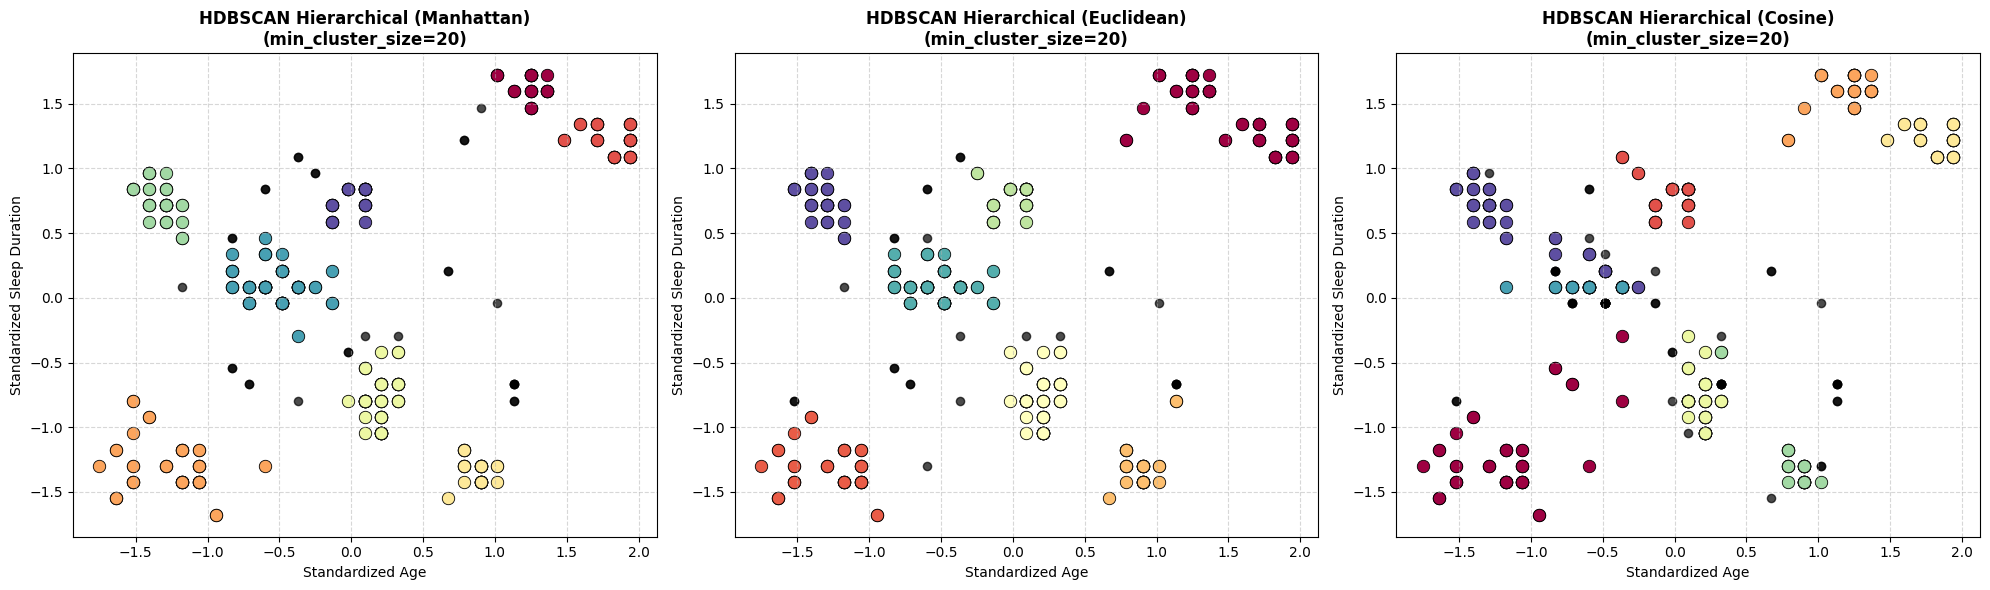

In [ ]:
fig_scatter, axes_scatter = plt.subplots(1, 3, figsize=(20, 6))

for idx, m in enumerate(metrics_list):
  ax = axes_scatter[idx]
  labels = labels_dict[m]

  unique_labels = set(labels)
  cluster_labels = sorted(list(unique_labels - {-1}))
  colors = plt.cm.Spectral(np.linspace(0, 1, len(cluster_labels)))

  noise_mask = labels == -1
  ax.scatter(
      X_2d[noise_mask, 0],
      X_2d[noise_mask, 1],
      c="black",
      s=35,
      marker="o",
      label="Noise / Outlier",
      alpha=0.7,
  )

  for i, k_label in enumerate(cluster_labels):
    col = colors[i]
    class_member_mask = labels == k_label
    xy = X_2d[class_member_mask]
    ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=[col],
        s=80,
        edgecolors="k",
        linewidth=0.6,
        label=f"Klaster {k_label}",
    )

  ax.set_title(
      f"HDBSCAN Hierarchical ({m.capitalize()})\n(min_cluster_size={min_cluster_size})",
      fontsize=12,
      fontweight="bold",
  )
  ax.set_xlabel("Standardized Age", fontsize=10)
  ax.set_ylabel("Standardized Sleep Duration", fontsize=10)
  ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Penjelasan per Baris

- **Baris 1** — `fig_scatter, axes_scatter = plt.subplots(1, 2, figsize=(15, 6))`: Membuat 2 subplot berdampingan (1 baris × 2 kolom).
- **Baris 2** — `for idx, m in enumerate(metrics_list):`: Loop dengan indeks & metrik.
- **Baris 3** — `ax = axes_scatter[idx]`: Pilih subplot ke-idx.
- **Baris 4** — `labels = labels_dict[m]`: Ambil label hasil HDBSCAN metrik ini.
- **Baris 5** — `unique_labels = set(labels)`: Semua label unik (termasuk noise).
- **Baris 6** — `cluster_labels = sorted(list(unique_labels - {-1}))`: Daftar label klaster **tanpa noise**, terurut.
- **Baris 7** — `colors = plt.cm.Spectral(np.linspace(0, 1, len(cluster_labels)))`: Palet warna sebanyak jumlah klaster.
- **Baris 8** — `noise_mask = labels == -1`: Mask untuk titik noise.
- **Baris 9–17** — `ax.scatter(...)`: Menggambar titik noise berwarna hitam (ukuran 35, transparansi 0.7, label "Noise / Outlier").
- **Baris 18** — `for i, k_label in enumerate(cluster_labels):`: Loop tiap klaster.
- **Baris 19** — `col = colors[i]`: Ambil warna klaster ini.
- **Baris 20** — `class_member_mask = labels == k_label`: Mask anggota klaster ini.
- **Baris 21** — `xy = X_2d[class_member_mask]`: Ambil titik anggota klaster ini.
- **Baris 22–29** — `ax.scatter(...)`: Gambar titik klaster (ukuran 80, tepi hitam, label "Klaster N").
- **Baris 30–34** — `ax.set_title(...)`: Judul subplot (`\n` = baris baru, tebal).
- **Baris 35** — `ax.set_xlabel("Standardized Age", fontsize=10)`: Label sumbu X.
- **Baris 36** — `ax.set_ylabel("Standardized Sleep Duration", fontsize=10)`: Label sumbu Y.
- **Baris 37** — `ax.grid(True, linestyle="--", alpha=0.5)`: Aktifkan grid.
- **Baris 38** — `plt.tight_layout()`: Rapikan jarak antar subplot.
- **Baris 39** — `plt.show()`: Tampilkan gambar.

Cell kelima menampilkan hasil clustering secara **visual** dalam bentuk **2 scatter plot berdampingan** (Euclidean & Cosine). Setiap klaster diberi warna berbeda, sedangkan titik **noise/outlier** (label -1) digambar **hitam**. Untuk tiap metrik, label unik diambil, warna dibuat sebanyak jumlah klaster (tanpa noise), lalu tiap klaster digambar sebagai satu kelompok titik. Noise digambar lebih dulu (agar tidak menutupi klaster), kemudian tiap klaster digambar dengan **legend** ("Klaster 0", "Klaster 1", dst.) supaya mudah dibedakan. Sumbu X = Standardized Age, sumbu Y = Standardized Sleep Duration. Visualisasi ini memudahkan membandingkan bagaimana HDBSCAN membentuk klaster pada kedua metrik.

## CELL 6 — Visualisasi Grafik Batang Grid 2x2


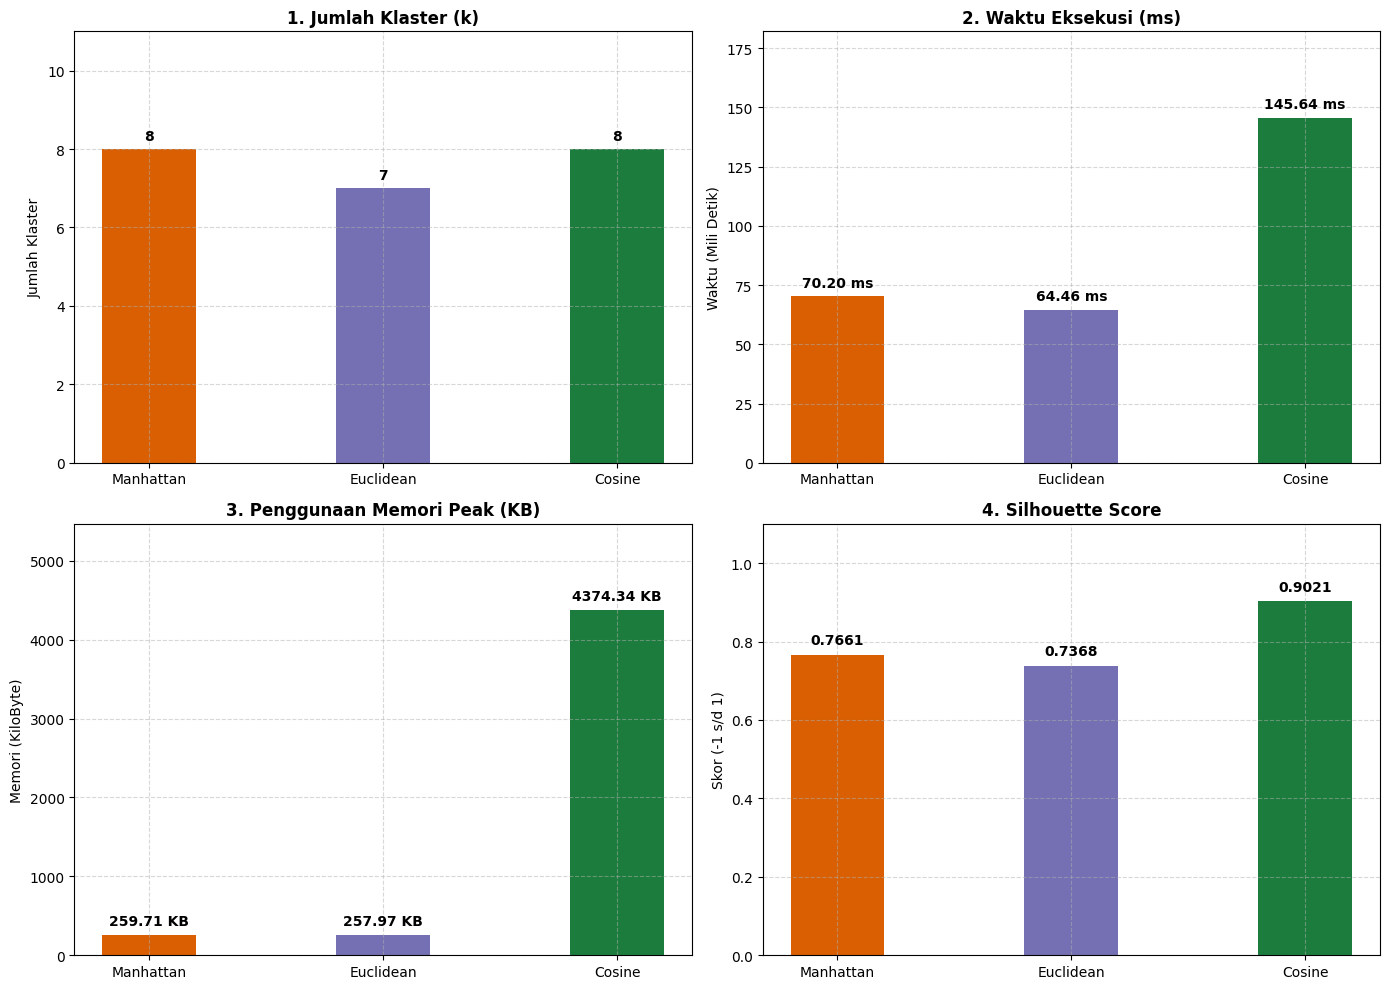

In [ ]:
metrics = df_results["Metrik Jarak"].tolist()
clusters = df_results["Jumlah Klaster"].astype(int).tolist()
times = [float(x) for x in df_results["Waktu Eksekusi (ms)"]]
memories = [float(x) for x in df_results["Memori Peak (KB)"]]
silhouettes = [
    float(x) if str(x) != "N/A" else 0.0 for x in df_results["Silhouette Score"]
]

bar_colors = ["#d95f02", "#7570b3", "#1b7c3d"]

fig_bar, axes_bar = plt.subplots(2, 2, figsize=(14, 10))

# 1. Jumlah Klaster
bars1 = axes_bar[0, 0].bar(metrics, clusters, color=bar_colors, width=0.4)
axes_bar[0, 0].set_title(
    "1. Jumlah Klaster (k)", fontweight="bold", fontsize=12
)
axes_bar[0, 0].set_ylabel("Jumlah Klaster", fontsize=10)
axes_bar[0, 0].set_ylim(0, max(clusters) + 3)
axes_bar[0, 0].grid(True, linestyle="--", alpha=0.5)
for bar in bars1:
  yval = bar.get_height()
  axes_bar[0, 0].text(
      bar.get_x() + bar.get_width() / 2,
      yval + 0.15,
      f"{int(yval)}",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

# 2. Waktu Eksekusi (ms)
bars2 = axes_bar[0, 1].bar(metrics, times, color=bar_colors, width=0.4)
axes_bar[0, 1].set_title(
    "2. Waktu Eksekusi (ms)", fontweight="bold", fontsize=12
)
axes_bar[0, 1].set_ylabel("Waktu (Mili Detik)", fontsize=10)
axes_bar[0, 1].set_ylim(0, max(times) * 1.25)
axes_bar[0, 1].grid(True, linestyle="--", alpha=0.5)
for bar in bars2:
  yval = bar.get_height()
  axes_bar[0, 1].text(
      bar.get_x() + bar.get_width() / 2,
      yval + (max(times) * 0.02),
      f"{yval:.2f} ms",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

# 3. Penggunaan Memori Peak (KB)
bars3 = axes_bar[1, 0].bar(metrics, memories, color=bar_colors, width=0.4)
axes_bar[1, 0].set_title(
    "3. Penggunaan Memori Peak (KB)", fontweight="bold", fontsize=12
)
axes_bar[1, 0].set_ylabel("Memori (KiloByte)", fontsize=10)
axes_bar[1, 0].set_ylim(0, max(memories) * 1.25)
axes_bar[1, 0].grid(True, linestyle="--", alpha=0.5)
for bar in bars3:
  yval = bar.get_height()
  axes_bar[1, 0].text(
      bar.get_x() + bar.get_width() / 2,
      yval + (max(memories) * 0.02),
      f"{yval:.2f} KB",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

# 4. Silhouette Score
bars4 = axes_bar[1, 1].bar(metrics, silhouettes, color=bar_colors, width=0.4)
axes_bar[1, 1].set_title("4. Silhouette Score", fontweight="bold", fontsize=12)
axes_bar[1, 1].set_ylabel("Skor (-1 s/d 1)", fontsize=10)
axes_bar[1, 1].set_ylim(0, 1.1)
axes_bar[1, 1].grid(True, linestyle="--", alpha=0.5)
for bar in bars4:
  yval = bar.get_height()
  axes_bar[1, 1].text(
      bar.get_x() + bar.get_width() / 2,
      yval + 0.02,
      f"{yval:.4f}",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

### Penjelasan per Baris

- **Baris 1** — `metrics = df_results["Metrik Jarak"].tolist()`: Ambil kolom metrik jadi list.
- **Baris 2** — `clusters = df_results["Jumlah Klaster"].astype(int).tolist()`: Ambil jumlah klaster, paksa integer.
- **Baris 3** — `times = [float(x) for x in ...]`: Ubah kolom waktu jadi list float.
- **Baris 4** — `memories = [float(x) for x in ...]`: Ubah kolom memori jadi list float.
- **Baris 5–7** — `silhouettes = [...]`: Ubah silhouette jadi float; `"N/A"` → `0.0`.
- **Baris 8** — `bar_colors = ["#5b82b6", "#62a758"]`: Warna batang (biru, hijau).
- **Baris 9** — `fig_bar, axes_bar = plt.subplots(2, 2, figsize=(12, 9))`: Grid 2×2 (4 subplot).
- **Baris 10** — `# 1. Jumlah Klaster`: Komentar subplot 1.
- **Baris 11** — `bars1 = axes_bar[0, 0].bar(...)`: Bar chart jumlah klaster (kiri-atas).
- **Baris 12–14** — `set_title(...)`: Judul subplot 1.
- **Baris 15** — `set_ylabel(...)`: Label sumbu Y.
- **Baris 16** — `set_ylim(0, max(clusters) + 3)`: Batas sumbu Y (ruang untuk angka).
- **Baris 17** — `grid(...)`: Aktifkan grid.
- **Baris 18–26** — Loop tiap batang: ambil tinggi (`yval`) lalu tulis angka di atas batang.
- **Subplot 2 (kanan-atas)** — Waktu eksekusi; batas Y = max×1.25; angka `"{yval:.2f} ms"`.
- **Subplot 3 (kiri-bawah)** — Memori peak; satuan KB.
- **Subplot 4 (kanan-bawah)** — Silhouette Score; batas Y 0–1.1; angka 4 desimal.
- **Baris akhir** — `plt.tight_layout()` lalu `plt.show()`: Rapikan jarak, tampilkan gambar.

Cell terakhir menyajikan hasil evaluasi dari Cell 4 dalam bentuk **grafik batang (bar chart)** yang disusun dalam **grid 2×2**. Data diambil langsung dari tabel `df_results`, lalu diubah menjadi list (metrik, jumlah klaster, waktu, memori, silhouette). Khusus Silhouette Score, nilai `"N/A"` diganti `0.0` agar tetap bisa digambar.

Empat subplot yang ditampilkan: **(1)** Jumlah Klaster, **(2)** Waktu Eksekusi (ms), **(3)** Memori Peak (KB), dan **(4)** Silhouette Score. Warna batang konsisten (Euclidean biru, Cosine hijau). Setiap batang diberi **label angka** di atasnya agar nilainya terbaca langsung. Dengan grafik ini, perbandingan performa HDBSCAN antara metrik Euclidean dan Cosine bisa dibaca cepat dan intuitif.